<h1 style="text-align:center;">ESCUELA POLITÉCNICA NACIONAL</h1>
<h2 style="text-align:center;">FACULTAD DE INGENIERÍA DE SISTEMAS</h2>
<h3 style="text-align:center;">INGENIERÍA EN CIENCIAS DE LA COMPUTACIÓN</h3>

**PERÍODO ACADÉMICO:** 2026-B  
**ASIGNATURA:** ICCD412 Métodos Numéricos  
**GRUPO:** GR2CC  
**TIPO DE INSTRUMENTO:** Notebook  
**FECHA DE ENTREGA LÍMITE:** 25/11/2026  
**ALUMNO:** Robayo Samuel

## Librerías utilizadas en el notebook

In [6]:
import math
import sys
import time
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

<hr style="border: 2px solid #444;">

# GUÍA DE USO del notebook y funciones auxiliares 
En esta sección se encuentran cosas que se deben considerar para el uso de métodos y ciertas funciones de mi notebook, una vez se termine esta parte de guía o de consideraciones voy a poner un título en rojo que dice "TEMAS DE CODIFICACION - INICIO", para que se distinga desde donde empieza.
## Formato de funciones para métodos posteriores
Más adelante en este notebook hay una sección que se llama "IMPLEMENTACIÓN DE MÉTODOS", en esta sección empieza la codificación de todos los métodos numéricos vistos en este bimestre, pero para dejar claras las reglas de uso de estos métodos es importante ver las siguientes tablas donde se presentan las funciones trigonométricas, exponenciales, logarítmicas y demás, para que se vea como se las debe escribir o usar en cada método y que este no falle por errores de tipeo o desconocimiento de su uso.

**Funciones Trigonométricas**

| Función Matemática | String válido (`func_str`) |
| ------------------ | -------------------------- |
| $\sin(x)$          | `"sin(x)"`                 |
| $\cos(x)$          | `"cos(x)"`                 |
| $\tan(x)$          | `"tan(x)"`                 |
| $\cot(x)$          | `"cot(x)"`                 |
| $\sec(x)$          | `"sec(x)"`                 |
| $\csc(x)$          | `"csc(x)"`                 |

**Funciones Exponenciales y Logarítmicas**

| Función Matemática | String válido (`func_str`)      |
| ------------------ | ------------------------------- |
| $e^x$              | `"exp(x)"`                      |
| $\ln(x)$           | `"ln(x)"`                       |
| $\log_{10}(x)$     | `"log(x, 10)"`                  |
| $\log_b(x)$        | `"log(x, b)"` (reemplazar `b`)  |

**Funciones Misceláneas**

| Función Matemática | String válido (`func_str`) |
| ------------------ | -------------------------- |
| $\sqrt{x}$         | `"sqrt(x)"`                |
| $\lvert x \rvert$  | `"Abs(x)"`                 |
| Polinomio típico   | `"x**2 + 3*x"`             |


Antes de cumplir con este tema de codificación de los temas que se deben codificar, quería aprovechar para definir dos funciones que van a ser muy útilies para el manejo de deciamles en resultados de casi todos los métodos o cosas que necesite en el el notebook, que son la de truncamiento y la de redondeo:
#### Funcion de truncamiento

In [5]:
def truncar(numero, decimales): #Esta la saqué de la implementación del profesor para polinomio de Taylor
    """
    Corta un número a una cantidad exacta de decimales sin redondear. Lo que hace es mover la coma a la derecha multiplicando por 10 elevado
    a los decimales, quita lo que sobra pasando a entero con int() y luego vuelve a dividir.

    Args:
    numero (float): El número original que quiero cortar o truncar.
    decimales (int): La cantidad de cifras decimales que quiero conservar.

    Returns:
    float: El número ya truncado con los decimales exactos que le pedí o mejor dicho que le pasé como parámetro.

    Example:
    >>> truncar(0.335555, 4)
    0.3355
    """
    factor = 10 ** decimales
    return int(numero * factor) / factor

In [2]:
x = 0.335555
x_truncado = truncar(x, 4)
print("Original:", x)
print("Truncamiento:", x_truncado)

Original: 0.335555
Truncamiento: 0.3355


#### Funcion de redondeo

In [4]:
def redondear(numero, decimales):
    """
    Esta redondea un número a una cantidad exacta de decimales. Lo que hace es mover la coma a la derecha multiplicando por 10 elevado a los 
    decimales, suma 0.5 si es positivo o resta 0.5 si es negativo para forzar el redondeo y pasa a entero con int() y luego vuelve a dividir.

    Args:
    numero (float): El número original que quiero redondear.
    decimales (int): La cantidad de cifras decimales que quiero conservar.

    Returns:
    float: El número ya redondeado con los decimales exactos que le pasé como parámetro.

    Example:
    >>> redondear(0.335, 2)
    0.34
    """
    factor = 10 ** decimales
    if numero >= 0:
        return int(numero * factor + 0.5) / factor
    else:
        return int(numero * factor - 0.5) / factor

In [101]:
x = 0.335555
x_redondeado = redondear(x, 4)
print("Original:", x)    
print("Redondeado:", x_redondeado)

Original: 0.335555
Redondeado: 0.3356


### Modos de aproximación 

En varios métodos uso el parámetro modo que se va a ver como modo = "corte" o como modo = "redondeo" y con eso segun qué parametro se le pase, el algoritmo de cada metodo verá cómo se ajustan los resultados.

 **modo = "corte" :** Elimina directamente los dígitos sobrantes sin modificar el último dígito que se conserva.  
  Ejemplo con 4 decimales: 3.14159   pasa a ser   3.1415

  
 **modo = redondeo":** Ajusta el último dígito conservado mirando el siguiente porque si es 5 o mayor suma 1, si es menor que 5 lo deja igual.  
  Ejemplo con 4 decimales: 3.14159   pasa a ser   3.1416

En la mayoría de métodos le dejé por defecto el modo de redondeo pero debo tener en cuenta que cuando un

Para cada método se va a hacer el uso de la siguiente función, para que se pueda pasarles las funciones matemáticas a tus métodos numéricos como texto sin tener que definir un def o un lambda a cada rato.

In [4]:
def obtener_funcion(f):
    """
    Convierte una función escrita en texto o mejor dicho string, en una función real de python lista para evaluar. La uso como ayuda en todos
    mis métodos numéricos para no tener que estar creando funciones lambda a cada rato. Si le paso un string, lo interpreta con sympy, le agrega
    soporte para el caso de cot, sec, csc y Abs, y me devuelve una función que siempre retorna un float. Si ya le paso una función hecha en python 
    la deja igual.

    Args:
    f (str o callable): La función matemática en formato de texto o una función de python ya definida.

    Returns:
    callable: Una función evaluable que recibe un número x y devuelve el resultado en float.

    Example:
    >>> f = obtener_funcion(f)  , esta es la manera que más voy a usar en mis métodos

                ó
                
    >>> mi_f = obtener_funcion("x**2 + 1")
    >>> mi_f(3)
    10.0
    """
    if isinstance(f, str):
        x = sp.Symbol('x')
        expr = sp.sympify(f)
        funciones_extra = {
            'cot': lambda v: 1 / math.tan(v),
            'sec': lambda v: 1 / math.cos(v),
            'csc': lambda v: 1 / math.sin(v),
            'Abs': abs,
        }
        func = sp.lambdify(x, expr, modules=[funciones_extra, "math"])
        return lambda val: float(func(val))
    return f

In [5]:
def signum(x):
    """
    Me dice el signo de un número devolviendo 1, -1 o 0. La uso sobre todo en métodos como el de bisección o de posición falsa para comprobar 
    si hay cambio de signo sin tener que multiplicar valores muy grandes o muy pequeños. Solo revisa si el número es mayor, menor o igual a cero.

    Args:
    x (float o int): El número al que le quiero sacar el signo.

    Returns:
    int: 1 si es positivo, -1 si es negativo y 0 si es cero.

    Example:
    >>> signum(-4.5)
    -1
    """
    if x > 0:
        return 1
    elif x < 0:
        return -1
    return 0

<hr style="border: 2px solid #444;">

<h2 style="color: #E74C3C;">TEMAS DE CODIFICACION - INICIO</h2>

## Métodos Analíticos


Un método analítico resuelve un problema matemático usando álgebra o cálculo para llegar a una fórmula exacta y con ella a un resultado exacto o definitivo al momento de reemplazar datos, sin tener que tantear o corregir errores. El ejemplo que planteo para este tema es el de el uso de la suma de Gauss la cual calcula la suma exacta de todos los números del 1 hasta n sin tener que sumarlos uno por uno. Su formula es:

$$
x = \frac{n(n + 1)}{2}
$$

Donde x será el resultado exacto de la suma de todos los numeros de 1 hasta n

##### Resolver la suma dado  n = 69:
$$
x = \frac{69(69 + 1)}{2}
$$


$$
x = \frac{69(70)}{2}
$$


$$
x = 69(35)
$$


$$
x = 2415
$$

In [2]:
n = 69
suma = (n * (n + 1)) // 2

print(f"La suma del 1 al {n} es: {suma}")

La suma del 1 al 69 es: 2415


<hr style="border: 2px solid #444;">

## Métodos Numéricos
Un método numérico es un procedimiento matemático que resuelve problemas mediante operaciones repetidas paso a paso, lo cual se conoce como iteraciones, con el fin de obtener una aproximación cada vez más cercana a la solución real. Se usa cuando un problema es demasiado complejo como para despejarse de forma directa o cuando no existe una fórmula exacta que pueda resolverlo.

##### Ejemplo de problema sin solución analítica: 
Dada la ecuación:
$$
x^x = 10
$$

Para resolver esta ecuación no sería útil un método analítico porque la x aparece simultáneamente en la base y en el exponente, lo que hace imposible despejarla mediante álgebra o funciones elementales y ni siquiera usando logaritmos se puede porque solo se transforma en:
$$x \ln(x) = \ln(10)$$

Para resolverla hay que usar un enfoque numérico reescribiendo la expresión como:
$$
f(x) = x^x - 10 = 0
$$

Aplicando métodos numérico como bisección, Newton-Raphson, punto fijo, etc., se puede conseguir una raíz aproximada para esta ecuación, la cual para esta ecuación es:
$$
x \approx 2.506184
$$

El proceso de obtención de la raíz aproximada se dará más adelante en los temas de codificación de métodos numéricos, específicamente en el método de Newton donde voy a poner una marca o algun comentario que recuerde que esta solución sale de ahí.

<hr style="border: 2px solid #444;">

## Exactitud vs Precisión
Exactitud es cuando los valores de cerca está un resultado del valor real y precisión es qué tan cerca están varios resultados entre sí, sin importar si están cerca del valor real.

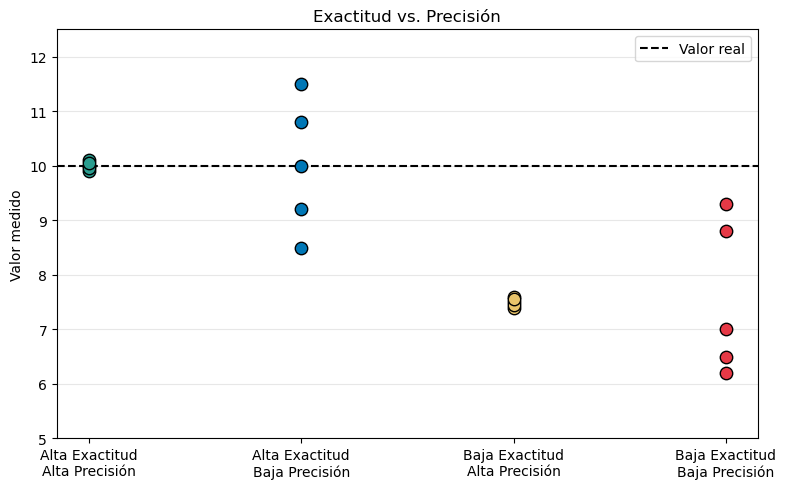

In [3]:
valor_real = 10
grupos = {
    "Alta Exactitud\nAlta Precisión": [9.9, 10.0, 10.1, 9.95, 10.05],
    "Alta Exactitud\nBaja Precisión": [8.5, 11.5, 9.2, 10.8, 10.0],
    "Baja Exactitud\nAlta Precisión": [7.4, 7.5, 7.6, 7.45, 7.55],
    "Baja Exactitud\nBaja Precisión": [6.2, 8.8, 7.0, 9.3, 6.5],
}
colores = ["#2a9d8f", "#0077b6", "#e9c46a", "#e63946"]

plt.figure(figsize=(8, 5))
plt.axhline(valor_real, color="black", linestyle="--", label="Valor real")
for i, ((nombre, datos), color) in enumerate(zip(grupos.items(), colores)):
    x = [i] * len(datos)
    plt.scatter(x, datos, color=color, s=80, edgecolor="black", zorder=5)
plt.xticks(range(len(grupos)), grupos.keys())
plt.ylabel("Valor medido")
plt.title("Exactitud vs. Precisión")
plt.ylim(5, 12.5)
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

<hr style="border: 2px solid #444;">

## Tipos de errores

#### Error por desbordamiento 
Ocurre cuando un cálculo produce un número que supera los límites finitos de memoria que el computador puede almacenar. Aquí a continuación muestro los valores límite que maneja python para números flotantes y enteros en este equipo:

In [4]:
print("Máximo flotante: ", sys.float_info.max)

Máximo flotante:  1.7976931348623157e+308


In [5]:
print("Mínimo flotante: ", sys.float_info.min)

Mínimo flotante:  2.2250738585072014e-308


In [6]:
print("Máximo entero: ", sys.maxsize)

Máximo entero:  2147483647


In [7]:
desbordamientoFloat = sys.float_info.max * 2
print("Desbordamiento de flotante:", desbordamientoFloat)

Desbordamiento de flotante: inf


<hr style="border: 2px solid #444;">

## Cálculo de errores
El cálculo de errores se realiza porque los métodos numéricos únicamente se aproximan a resultados reales pero no  dan valores exactos y por eso medir ese margen de error de cada aproximación respecto al valor real permite saber qué tan confiable es un resultado. Otra cosa para la que sirven es como criterio de parada para decidir cuándo detener un proceso iterativo cuando este logra alcanzar una tolerancia aceptable y esto evita que pequeñas imprecisiones se hagan como una bola de nieve que cada vez da resultados más absurdos o distantes.

#### Error real

In [50]:
def error_real(p, p_aprox):
    """
    Esta función calcula el error real entre un valor exacto y su aproximación. Es sencillita, solo le paso ambos valores y hago la resta directa.
    Args:
    p (float): El valor real o exacto que tengo como referencia.
    p_aprox (float): El valor aproximado que obtuve de algún método.

    Returns:
    float: La diferencia exacta entre p y p_aprox con todo y signo.

    Example:
    >>> error_real(math.pi, 3.1416)
    -7.346410206832132e-06
    """
    return p - p_aprox

In [80]:
print(f"Error real: {error_real(math.pi, 3.1416):.6e}")

Error real: -7.346410e-06


#### Error absoluto

In [48]:
def error_absoluto(p, p_aprox):
  
    """
    Esta función calculca el error absoluto entre un valor exacto y su aproximación. Le paso el valor real y el aproximado, y le saco el valor 
    absoluto a su diferencia.
    
    Args:
    p (float): El valor real o exacto de referencia.
    p_aprox (float): El valor aproximado que calculé con algún método.

    Returns:
    float: La distancia positiva entre p y p_aprox.

    Example:
    >>> error_absoluto(math.e, 2.7183)
    1.817154095452424e-05
    """ 
    return abs(p - p_aprox)

In [82]:
print(f"Error absoluto: {error_absoluto(math.e, 2.7183):.6e}")

Error absoluto: 1.817154e-05


#### Error relativo

In [49]:
def error_relativo(p, p_aprox):
    """
    Esta calcula el error relativo comparando el error con el tamaño del valor real. Aqui primero valido que p no sea cero para no dividir
    para cero y luego saco el valor absoluto de la diferencia dividida para p.

    Args:
    p (float): El valor real o exacto de referencia que tiene que ser distinto de 0.
    p_aprox (float): El valor aproximado que obtuve de algún método.

    Returns:
    float: La proporción positiva del error respecto al valor real.

    Example:
    >>> error_relativo(math.sqrt(2), 1.4142)
    9.59004596671574e-06
    """
    if p == 0:
        raise ValueError("El valor real 'p' no puede ser cero.")
    return abs((p - p_aprox) / p)

In [13]:
print(f"Error relativo: {error_relativo(math.sqrt(2), 1.4142):.6e}")

Error relativo: 9.590046e-06


#### Error relativo porcentual

In [51]:
def error_relativo_porcentual(p, p_aprox):
    """
    Calculo el error relativo expresado en porcentaje. Es básicamente el mismo error relativo solo que aquí está multiplicado por 100 para
    leerlo más fácil como un porcentaje. Reutilizo mi función error_relativo para no repetir lo mismo dos veces.

    Args:
    p (float): El valor real o exacto de referencia que debe ser distinto de 0.
    p_aprox (float): El valor aproximado que obtuve de algún método.

    Returns:
    float: El porcentaje de error respecto al valor real.

    Example:
    >>> error_relativo_porcentual(math.tau, 6.28)
    0.05069573828972128
    """
    return error_relativo(p, p_aprox) * 100

In [86]:
print(f"Error relativo porcentual: {error_relativo_porcentual(math.tau, 6.28):.2f}%")

Error relativo porcentual: 0.05%


<hr style="border: 2px solid #444;">

## Aritmética de computador 

In [17]:
def fl(x, cifras, modo="redondeo"):
    """
    Convierte un número a aritmética de punto flotante con una cantidad exacta de cifras significativas. La uso para simular cómo guarda
    los números un computador con precisión limitada, ya sea por redondeo o por corte. Si el número es 0 devuelve 0.0 directo y si es que no, 
    calcula la potencia de 10 correspondiente, mueve la coma con un factor, aplica truncamiento o redondeo según el modo y vuelve a dejar el 
    número en su escala original.

    Args:
    x (float): El número original que quiero ajustar.
    cifras (int): La cantidad de cifras significativas que quiero conservar.
    modo (str): El método de ajuste, puede ser "redondeo" o "corte".

    Returns:
    float: El número ajustado a las cifras significativas indicadas.

    Example:
    >>> fl(3.14159, 4)
    3.142
    """
    if x == 0:
        return 0.0
    n = math.floor(math.log10(abs(x))) + 1
    factor = 10 ** (cifras - n)
    if modo == "corte":
        return math.trunc(x * factor) / factor
    return round(x * factor) / factor

In [16]:
def formato_fl(x, cifras, modo="redondeo"):
    """
    Me devuelve el número en texto con la notación o formato requerido por el pdf del profesor, solo para imprimirlo.

    Args:
    x (float): Número a formatear.
    cifras (int): Cantidad de cifras significativas.
    modo (str): "redondeo" o "corte".

    Returns:
    str: El número en formato "0.d1d2d3... * 10^n".

    Example:
    >>> formato_fl(3.14159, 4)
    '0.3142 * 10^1'
    """
    if x == 0:
        return "0.0 * 10^0"

    signo = "-" if x < 0 else ""
    n = math.floor(math.log10(abs(x))) + 1
    mantisa = abs(x) / (10 ** n)

    if modo == "corte":
        mantisa = truncar(mantisa, cifras)
    else:
        mantisa = redondear(mantisa, cifras)
        if mantisa >= 1.0:
            mantisa /= 10
            n += 1

    return f"{signo}{mantisa:.{cifras}f} * 10^{n}"

In [10]:
print(formato_fl(3.14159, 4))                        
print(formato_fl(-13844.2, 4, "corte")) 

0.3142 * 10^1
-0.1384 * 10^5


In [15]:
def suma_fl(x, y, cifras, modo="redondeo"):
    """
    Suma dos números usando aritmética de punto flotante con las cifras que le pida.

    Args:
    x (float): Primer número.
    y (float): Segundo número.
    cifras (int): Cantidad de cifras significativas.
    modo (str): "redondeo" o "corte".
   
    Returns:
    float: Resultado de la suma ya ajustado con fl.

    Example:
    >>> suma_fl(1/3, 2/7, 5)
    0.61904
    """
    return fl(fl(x, cifras, modo) + fl(y, cifras, modo), cifras, modo)

In [24]:
res_suma = suma_fl(1/3, 2/7, 5)
print("Suma:", formato_fl(res_suma, 5))

Suma: 0.61904 * 10^0


In [14]:
def resta_fl(x, y, cifras, modo="redondeo"):
    """
    Resta dos números en aritmética de punto flotante con las cifras que le pida.

    Args:
    x (float): Número al que le resto.
    y (float): Número que resto.
    cifras (int): Cantidad de cifras significativas.
    modo (str): "redondeo" o "corte".
    
    Returns:
    float: Resultado de la resta ya ajustado con fl.

    Example:
    >>> resta_fl(138.45, 12.678, 4, modo="corte")
    125.7
    """
    return fl(fl(x, cifras, modo) - fl(y, cifras, modo), cifras, modo)

In [19]:
res_resta = resta_fl(138.45, 12.678, 4, modo="corte")
print("Resta:", formato_fl(res_resta, 4, modo="corte"))

Resta: 0.1257 * 10^3


In [13]:
def mult_fl(x, y, cifras, modo="redondeo"):
    """
    Multiplica dos números en aritmética de punto flotante con las cifras que le pida.

    Args:
    x (float): Primer factor.
    y (float): Segundo factor.
    cifras (int): Cantidad de cifras significativas.
    modo (str): "redondeo" o "corte".
    Valor por defecto: "redondeo".

    Returns:
    float: Producto ya ajustado con fl.

    Example:
    >>> mult_fl(2.71828, 5/7, 3)
    1.94
    """
    return fl(fl(x, cifras, modo) * fl(y, cifras, modo), cifras, modo)

In [18]:
res_mult = mult_fl(2.71828, 5/7, 3)
print("Multiplicacion:", formato_fl(res_mult, 3))

Multiplicacion: 0.194 * 10^1


In [20]:
def div_fl(x, y, cifras, modo="redondeo"):
    """
    Divide dos números en aritmética de punto flotante y evita la división para cero.

    Args:
    x (float): Dividendo.
    y (float): Divisor.
    cifras (int): Cantidad de cifras significativas.
    modo (str): "redondeo" o "corte".
   
    Returns:
    float o str: Cociente ajustado con fl, o un mensaje de error si el divisor queda en 0.

    Example:
    >>> div_fl(1/3, 2/7, 5)
    1.1667
    """
    y_fl = fl(y, cifras, modo)
    if y_fl == 0:
        return "Error de división para cero"
    return fl(fl(x, cifras, modo) / y_fl, cifras, modo)

In [21]:
res_div = div_fl(1.41421, 0.714251, 5, modo="corte")
print("Division:", formato_fl(res_div, 5, modo="corte"))

Division: 0.19799 * 10^1


<hr style="border: 2px solid #444;">

## Representación numérica de 32 y 64 bits

In [24]:
def decimal_a_ieee754(numero, bits=32): 
    """
    Convierte un número decimal a su representación binaria en estándar IEEE 754 de 32 o 64 bits. Saca el bit de signo, normaliza la parte entera 
    y fraccionaria para armar la mantisa y le suma el sesgo al exponente que puede ser 127 para 32 bits o 1023 para 64 bits.

    Args:
    numero (float): El número decimal que quiero pasar a binario.
    bits (int): Precisión a usar, solo admite 32 o 64.
    Valor por defecto: 32 

    Returns:
    str: Cadena de unos y ceros con el signo, exponente y mantisa juntos.

    Example:
    >>> decimal_a_ieee754(5.5, 32)
    '01000000101100000000000000000000'
    """
    if bits == 32:
        exp_bits, mantisa_bits, sesgo = 8, 23, 127
    elif bits == 64:
        exp_bits, mantisa_bits, sesgo = 11, 52, 1023
    else:
        raise ValueError("Solo se admite 32 o 64 bits.")

    if numero == 0:
        return "0" * bits

    s = "1" if numero < 0 else "0"
    x = abs(numero)
 
    entero = int(x)
    frac = x - entero

    bin_entero = bin(entero)[2:] if entero > 0 else ""
    
    if entero > 0:
        exp = len(bin_entero) - 1
        mantisa = bin_entero[1:]
        while len(mantisa) < mantisa_bits and frac > 0:
            frac *= 2
            bit = int(frac)
            mantisa += str(bit)
            frac -= bit
    else:
        exp = 0
        while frac < 1 and frac > 0:
            frac *= 2
            exp -= 1
        frac -= 1  
        mantisa = ""
        while len(mantisa) < mantisa_bits and frac > 0:
            frac *= 2
            bit = int(frac)
            mantisa += str(bit)
            frac -= bit

    mantisa = mantisa[:mantisa_bits].ljust(mantisa_bits, "0")
    c = exp + sesgo
    c_bin = format(c, f"0{exp_bits}b")

    return f"{s}{c_bin}{mantisa}"

In [25]:
x = 263.3  # Cambiar este valor por el número que quiera convertir en el examen o deberes o lo que sea
print(f"Número {x} en 32 bits:", decimal_a_ieee754(x, 32))
print(f"Número {x} en 64 bits:", decimal_a_ieee754(x, 64))

Número 263.3 en 32 bits: 01000011100000111010011001100110
Número 263.3 en 64 bits: 0100000001110000011101001100110011001100110011001100110011001101


In [28]:
def ieee754_a_decimal(binario):
    """
    Convierte una cadena binaria en estándar IEEE 754 (32 o 64 bits) de vuelta a decimal. Le quita los espacios si es que por ahí trae, separa 
    el signo, el exponente y la mantisa según el largo de la cadena y aplica la fórmula para reconstruir el número.

    Args:
    binario (str): Cadena de 32 o 64 bits (puede tener espacios).

    Returns:
    float: El número decimal equivalente.

    Example:
    >>> ieee754_a_decimal("01000000101100000000000000000000")
    5.5
    """
    b = binario.replace(" ", "")
    if len(b) == 32:
        exp_bits, sesgo = 8, 127
    elif len(b) == 64:
        exp_bits, sesgo = 11, 1023
    else:
        raise ValueError("La cadena debe tener 32 o 64 bits.")

    if set(b[1:]) == {"0"}:
        return 0.0

    s = int(b[0])
    c = int(b[1:1 + exp_bits], 2)
    mantisa_str = b[1 + exp_bits:]

    f = 0.0
    for i, bit in enumerate(mantisa_str, start=1):
        if bit == "1":
            f += (1 / 2) ** i

    return ((-1) ** s) * (2 ** (c - sesgo)) * (1 + f)

In [29]:
bin_32 = "10111111010010001111111000011001" 
bin_64 = "0100000000001001101011111101001111111001111010100000001001011000"

print(f"Binario {bin_32} de 32 bits a decimal:", ieee754_a_decimal(bin_32))
print(f"Binario {bin_64} de 64 bits a decimal:", ieee754_a_decimal(bin_64))

Binario 10111111010010001111111000011001 de 32 bits a decimal: -0.7851272225379944
Binario 0100000000001001101011111101001111111001111010100000001001011000 de 64 bits a decimal: 3.210853531316655


<hr style="border: 2px solid #444;">

## Convergencia, divergencia y tolerancia
Para este tema utilicé gráficas porque el profesor había dicho que era posible hacerlo y las gráficas que se muestran a continuación están puestas con funciones trigonométricas y exponenciales, porque este tipo de funciones permite generar gráficas con bastantes oscilaciones y eso ayuda a que visualizar el ejemplo de cada tema sea mucho más fácil y entendible.

#### Convergencia
Cuando en cada iteración el método se va acercando cada vez más a la respuesta real. La siguiente gráfica muestra lo que es este comportamiento:

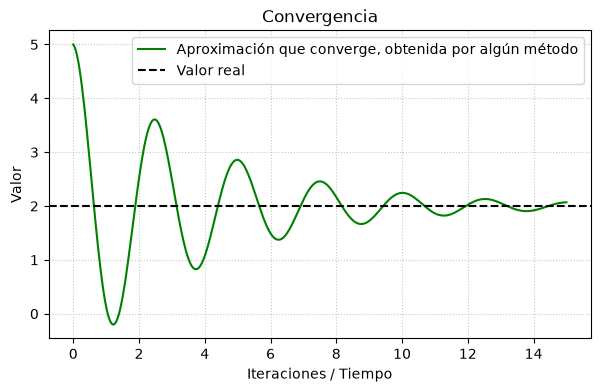

In [32]:
x = np.linspace(0, 15, 400)
valor_real = 2.0
y_conv = valor_real + 3 * np.exp(-0.25 * x) * np.cos(2.5 * x)

plt.figure(figsize=(7, 4))
plt.plot(x, y_conv, color='green', label='Aproximación que converge, obtenida por algún método')
plt.axhline(valor_real, color='black', linestyle='--', label=f'Valor real')

plt.title('Convergencia')
plt.xlabel('Iteraciones / Tiempo')
plt.ylabel('Valor')
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend()
plt.show()

#### Divergencia
Es lo contrario de la convergencia ya que aquí los resultados se alejan, rebotan sin control o se disparan o nunca llegan a nada. La siguiente gráfica nos muestra este comportamiento:

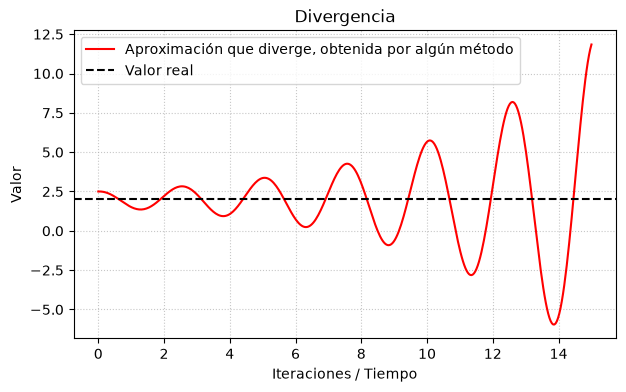

In [143]:
y_div = valor_real + 0.5 * np.exp(0.2 * x) * np.cos(2.5 * x)

plt.figure(figsize=(7, 4))
plt.plot(x, y_div, color='red', label='Aproximación que diverge, obtenida por algún método')
plt.axhline(valor_real, color='black', linestyle='--', label=f'Valor real')

plt.title('Divergencia')
plt.xlabel('Iteraciones / Tiempo')
plt.ylabel('Valor')
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend()
plt.show()

#### Tolerancia
Es el margen de error mínimo que acepto para decir que ya está lo suficientemente cerca y frenar el algoritmo. La siguiente gráfica muestra lo que es esa zona aceptable:

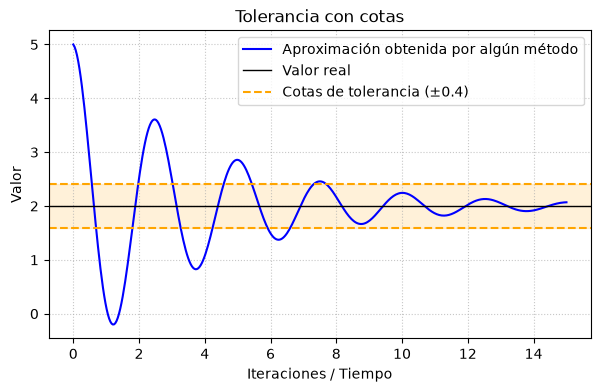

In [34]:
tolerancia = 0.4
cota_sup = valor_real + tolerancia
cota_inf = valor_real - tolerancia

fuera = np.where(np.abs(y_conv - valor_real) >= tolerancia)[0]
idx_parada = fuera[-1] + 1
x_parada, y_parada = x[idx_parada], y_conv[idx_parada]

plt.figure(figsize=(7, 4))
plt.plot(x, y_conv, color='blue', label='Aproximación obtenida por algún método')
plt.axhline(valor_real, color='black', linestyle='-', linewidth=1, label=f'Valor real')

plt.axhline(cota_sup, color='orange', linestyle='--', label=f'Cotas de tolerancia (±{tolerancia})')
plt.axhline(cota_inf, color='orange', linestyle='--')
plt.axhspan(cota_inf, cota_sup, color='orange', alpha=0.15)

plt.title('Tolerancia con cotas')
plt.xlabel('Iteraciones / Tiempo')
plt.ylabel('Valor')
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend()
plt.show()

<hr style="border: 2px solid #444;">

## Criterios de parada
Las siguientes funciones son solo ejemplos para mostrar cómo funciona cada criterio de parada por separado. No las voy a reutilizar en los métodos de bisección, Newton, secante, etc., porque cada algoritmo tiene su propio bucle, imprime su tabla diferente y maneja sus casos especiales, así que prefiero escribir la condición directamente en cada método para que el código sea más fácil de leer y seguir.

In [89]:
def parada_error_absoluto(p0, tol=1e-6):
    """
    Esta función es solo un ejemplo de criterio de parada usando el error absoluto para aproximar raíz de 2. Se detiene cuando la diferencia 
    entre la aproximación actual y la anterior es menor a tol.

    Args:
    p0 (float): Valor inicial para arrancar las iteraciones.
    tol (float): Tolerancia máxima permitida.
    Valor por defecto: 1e-6.

    Returns:
    None: Solo imprime en qué iteración paró y el valor aproximado.

    Example:
    >>> parada_error_absoluto(1.0)
    Detenido por error absoluto en la iteración 5, el valor aproximado es p = 1.4142135623730951
    """
    p_ant = p0
    i = 0
    while True:
        i += 1
        p_act = p_ant - (p_ant**2 - 2) / (2 * p_ant)
        if error_absoluto(p_act, p_ant) < tol:
            print(f"Detenido por error absoluto en la iteración {i}, el valor aproximado es p = {p_act}")
            break
        p_ant = p_act

parada_error_absoluto(1.0)

Detenido por error absoluto en la iteración 5, el valor aproximado es p = 1.4142135623730951


In [118]:
def parada_error_relativo(p0, tol=1e-6):
    """
    Ejemplo de criterio de parada usando el error relativo para aproximar raíz de 2 que se detiene cuando el error relativo entre la iteración
    actual y la anterior es menor a tol.

    Args:
    p0 (float): Valor inicial para arrancar las iteraciones.
    tol (float): Tolerancia máxima permitida.
    Valor por defecto: 1e-6.

    Returns:
    None: Solo imprime en qué iteración paró y el valor aproximado.

    Example:
    >>> parada_error_relativo(1.0)
    Detenido por error relativo en la iteración 5, el valor aproximado es p = 1.4142135623730951
    """
    p_ant = p0
    i = 0
    while True:
        i += 1
        p_act = p_ant - (p_ant**2 - 2) / (2 * p_ant)
        if p_act != 0 and error_relativo(p_act, p_ant) < tol:
            print(f"Detenido por error relativo en la iteración {i}, el valor aproximado es p = {p_act}")
            break
        p_ant = p_act

parada_error_relativo(1.0)

Detenido por error relativo en la iteración 5, el valor aproximado es p = 1.4142135623730951


In [156]:
def parada_valor_funcion(p0, tol=1e-6):
    """
    Aquí en esta funcion se ve un ejemplo de criterio de parada evaluando qué tan cerca está f(p) de cero para raíz de 2 que se detienee
    cuando el valor absoluto de p**2 - 2 es menor al valor de tol.

    Args:
    p0 (float): Valor inicial para arrancar las iteraciones.
    tol (float): Tolerancia máxima permitida.
    Valor por defecto: 1e-6.

    Returns:
    None: Solo imprime en qué iteración paró y el valor aproximado.

    Example:
    >>> parada_valor_funcion(1.0)
    Detenido por valor de la función en la iteración 4, el valor aproximado es p = 1.4142135623746899
    """
    p = p0
    i = 0
    while True:
        i += 1
        p = p - (p**2 - 2) / (2 * p)
        if error_absoluto(p**2 - 2, 0) < tol:
            print(f"Detenido por valor de la función en la iteración {i}, el valor aproximado es p = {p}")
            break

parada_valor_funcion(1.0)

Detenido por valor de la función en la iteración 4, el valor aproximado es p = 1.4142135623746899


In [161]:
def parada_iteraciones(p0, K=4):
    """
    Este es el criterio de parada por límite de iteraciones para aproximar el número áureo que se detiene en cuanto cumple exactamente K
    iteraciones, sin importar el error.

    Args:
    p0 (float): Valor inicial para arrancar las iteraciones.
    K (int): Número máximo de iteraciones que quiero hacer.
    Valor por defecto: 4.

    Returns:
    None: Solo imprime el límite de iteraciones y el valor aproximado.

    Example:
    >>> parada_iteraciones(1.5, K=4)
    Detenido por número de iteraciones (K=4), el valor aproximado es p = 1.618033988749895
    """
    p = p0
    i = 0
    while i < K:
        p = p - (p**2 - p - 1) / (2 * p - 1)
        i += 1
    print(f"Detenido por número de iteraciones (K={K}), el valor aproximado es p = {p}")

parada_iteraciones(1.5, K=4)

Detenido por número de iteraciones (K=4), el valor aproximado es p = 1.618033988749895


In [164]:
def parada_tiempo(p0, T_ms=5):
    """
    Función para criterio de parada por tiempo límite para resolver cos(p) - p = 0. Esta función itera hasta que se cumplan los milisegundos
    que le puse en T_ms.

    Args:
    p0 (float): Valor inicial para arrancar las iteraciones.
    T_ms (float): Tiempo máximo de ejecución en milisegundos.
    Valor por defecto: 5.

    Returns:
    None: Solo imprime el tiempo que tardó, cuántas iteraciones hizo y el valor aproximado.

    Example:
    >>> parada_tiempo(0.5, T_ms=5)
    Detenido por tiempo (5.00 ms) tras 2800 iteraciones, el valor aproximado es p = 0.7390851332151607
    """
    p = p0
    i = 0
    inicio = time.perf_counter()
    while (time.perf_counter() - inicio) * 1000 < T_ms:
        p = p - (math.cos(p) - p) / (-math.sin(p) - 1)
        i += 1
    tiempo_total = (time.perf_counter() - inicio) * 1000
    print(f"Detenido por tiempo ({tiempo_total:.2f} ms) tras {i} iteraciones, el valor aproximado es p = {p}")

parada_tiempo(0.5, T_ms=5)

Detenido por tiempo (5.00 ms) tras 10119 iteraciones, el valor aproximado es p = 0.7390851332151607


<hr style="border: 2px solid #444;">

## IMPLEMENTACIÓN DE MÉTODOS


## Método de bisección

In [165]:
def biseccion(f, a, b, TOL, N0, modo="redondeo", decimales=9):
    """
    Esta función busca una raíz de la función f en el intervalo [a, b] usando el método de bisección y imprime la tabla de cada iteración y
    se detiene cuando el error es menor a TOL o llega a N0.

    Args:
    f (callable o str): Función a evaluar (puede ser texto o función de Python).
    a (float): Extremo izquierdo del intervalo.
    b (float): Extremo derecho del intervalo.
    TOL (float): Tolerancia máxima permitida.
    N0 (int): Número máximo de iteraciones.
    modo (str): "redondeo" o "corte", con valor por defecto "redondeo".
    decimales (int): Cantidad de decimales para mostrar y devolver el resultado, por defecto 9


    Returns:
    float o str: La raíz aproximada ya ajustada, o un mensaje de error si no hay cambio de signo o si falla tras N0 iteraciones.

    Example:
    >>> biseccion("x**2 - 2", 1, 2, 1e-4, 20)
    Tabla con valores de cada iteración y raíz 
    1.414245605
    """
    f = obtener_funcion(f)
    if f(a) * f(b) >= 0:
        return "Error: El intervalo no contiene una raíz garantizada."
    
    ajustar = truncar if modo == "corte" else redondear
    ancho = decimales + 6
    print(f"{'i':<4} | {'a':<{ancho}} | {'b':<{ancho}} | {'p':<{ancho}} | {'sgn(f(a))':<9} | {'sgn(f(b))':<9} | {'sgn(f(p))':<9} | {'Error':<13}")
    
    i = 1
    p_ant = None
    
    while i <= N0:
        p = a + (b - a) / 2
        fa, fb, fp = f(a), f(b), f(p)
        
        if i == 1:
            error_str = f"{'-':<13}"
            error = float('inf')
        else:
            error = error_absoluto(p, p_ant)
            error_str = f"{error:<13.6e}"
            
        print(f"{i:<4} | {ajustar(a, decimales):<{ancho}} | {ajustar(b, decimales):<{ancho}} | {ajustar(p, decimales):<{ancho}} | {signum(fa):<9} | {signum(fb):<9} | {signum(fp):<9} | {error_str}")
        
        if (i > 1 and error < TOL) or error_absoluto(fp, 0) == 0:
            return ajustar(p, decimales)
            
        p_ant = p
        i += 1
        if fa * fp > 0:
            a = p
        else:
            b = p
            
    return f"El método falló después de {N0} iteraciones."

In [166]:
f_str = "x**3 - 7*x**2 + 14*x -6"

res_red = biseccion(f_str, 0, 1, 1e-5, 40, modo="redondeo", decimales=9)
print(f"\nRaíz aproximada con redondeo: {res_red}\n")

res_corte = biseccion(f_str, 0, 1, 1e-5, 40, modo="corte", decimales=9)
print(f"\nRaíz aproximada con corte: {res_corte}")

i    | a               | b               | p               | sgn(f(a)) | sgn(f(b)) | sgn(f(p)) | Error        
1    | 0.0             | 1.0             | 0.5             | -1        | 1         | -1        | -            
2    | 0.5             | 1.0             | 0.75            | -1        | 1         | 1         | 2.500000e-01 
3    | 0.5             | 0.75            | 0.625           | -1        | 1         | 1         | 1.250000e-01 
4    | 0.5             | 0.625           | 0.5625          | -1        | 1         | -1        | 6.250000e-02 
5    | 0.5625          | 0.625           | 0.59375         | -1        | 1         | 1         | 3.125000e-02 
6    | 0.5625          | 0.59375         | 0.578125        | -1        | 1         | -1        | 1.562500e-02 
7    | 0.578125        | 0.59375         | 0.5859375       | -1        | 1         | 1         | 7.812500e-03 
8    | 0.578125        | 0.5859375       | 0.58203125      | -1        | 1         | -1        | 3.906250e-03 
9

## Cálculo de número de iteraciones necesarias

Partimos de la cota de error del método de bisección:
$$|p_n - p| \le \frac{b - a}{2^n}$$

Para garantizar una precisión dada por una tolerancia $\text{TOL}$, imponemos:
$$\frac{b - a}{2^n} \le \text{TOL}$$

Despejamos $2^n$:
$$\frac{b - a}{\text{TOL}} \le 2^n$$

Aplicamos $\log_2$ a ambos lados de la desigualdad:
$$\log_2\left(\frac{b - a}{\text{TOL}}\right) \le n$$

Como $n$ debe ser un número entero, tomamos el entero superior:
$$n =  \log_2\left(\frac{b - a}{\text{TOL}}\right) $$

In [236]:
def iteraciones_biseccion(a, b, TOL):
    """
    Calcula el número mínimo de iteraciones que necesita el método de bisección para alcanzar una tolerancia en el intervalo [a, b].

    Args:
    a (float): Extremo izquierdo del intervalo.
    b (float): Extremo derecho del intervalo.
    TOL (float): Tolerancia máxima permitida que debe ser mayor que cero

    Returns:
    int: Cantidad mínima de iteraciones redondeada hacia arriba.

    Example:
    >>> iteraciones_biseccion(1, 2, 1e-3)
    10
    """
    if TOL <= 0:
        raise ValueError("La tolerancia debe ser mayor que cero.")
    if a == b:
        raise ValueError("Los extremos 'a' y 'b' no pueden ser iguales.")

    n = math.log2(abs(b - a) / TOL)
    return math.ceil(n)

In [171]:
a, b, tol = 0, 5, 1e-5
n = iteraciones_biseccion(a, b, tol)
print(f"Para [{a}, {b}] con tol={tol} se necesitan mínimo {n} iteraciones.")

Para [0, 5] con tol=1e-05 se necesitan mínimo 19 iteraciones.


## Método de Newton-Raphson

In [237]:
def derivada(f, x):
    """
    Aproxima la derivada de la función f en el punto x usando un paso h muy pequeño 1e-7 porque en realidad la definicion de derivada es con h que 
    tiende a cero pero para simular el cero se usa ese numero pequeño

    Args:
    f (callable): Función de python a derivar.
    x (float): Punto donde quiero evaluar la derivada

    Returns:
    float: Valor aproximado de la derivada f'(x).

    Example:
    >>> derivada(lambda x: x**2, 3)
    6.000000087880153
    """
    h = 1e-7
    return (f(x + h) - f(x)) / h

In [238]:
def newton(f, p0, TOL, N0, modo="redondeo", decimales=9):
    """
    Busca una raíz de la función f arrancando desde p0 usando el método de Newton-raphson donde imprime la tabla de iteraciones y para cuando
    el error es menor a TOL o llega a N0.

    Args:
    f (callable o str): Función a evaluar que puede ser en texto o función de python.
    p0 (float): Valor inicial para arrancar las iteraciones.
    TOL (float): Tolerancia máxima permitida.
    N0 (int): Número máximo de iteraciones
    modo (str): "redondeo" o "corte" con redondeo por defecto
    decimales (int): Cantidad de decimales para mostrar y devolver el resultado con 9 por defecto.

    Returns:
    float o str: La raíz aproximada ya ajustada o un mensaje de error si la derivada da cero o si falla tras N0 iteraciones.

    Example:
    >>> newton("x**2 - 2", 1.0, 1e-6, 20)
    Se imprime la tabla de ejecución y la raíz también
    1.414213562
    """
    f = obtener_funcion(f)
    ajustar = truncar if modo == "corte" else redondear
    ancho = decimales + 6
    
    print(f"{'i':<5} | {'p_n':<{ancho}} | {'Error':<15}")
    print(f"{0:<5} | {ajustar(p0, decimales):<{ancho}} | {'-':<15}")
    
    i = 1
    while i <= N0:
        df_p0 = derivada(f, p0)
        if df_p0 == 0:
            return "Error hay división para cero  en la derivada"
            
        p = p0 - f(p0) / df_p0
        error = error_absoluto(p, p0)
        
        print(f"{i:<5} | {ajustar(p, decimales):<{ancho}} | {error:<15.6e}")
        
        if error < TOL:
            return ajustar(p, decimales)
            
        i += 1
        p0 = p
        
    return f"El método falló después de {N0} iteraciones."

In [239]:
f_str = "x^x - 10"
#AQUI ESTÁ LA ECUACIÓN QUE PUSE EN EL TEMA DE CODIFICACIÓN DE "MÉTODOS NUMÉRICOS"
res_red = newton(f_str, 3.5, 1e-20, 20, modo="redondeo", decimales=9)
print(f"\nRaíz aproximada con redondeo: {res_red}\n")

res_corte = newton(f_str, 3.5, 1e-20, 20, modo="corte", decimales=9)
print(f"\nRaíz aproximada con corte: {res_corte}")

i     | p_n             | Error          
0     | 3.5             | -              
1     | 3.11144162      | 3.885584e-01   
2     | 2.780089926     | 3.313517e-01   
3     | 2.573780315     | 2.063096e-01   
4     | 2.510843817     | 6.293650e-02   
5     | 2.506207167     | 4.636650e-03   
6     | 2.506184146     | 2.302117e-05   
7     | 2.506184146     | 5.659890e-10   
8     | 2.506184146     | 0.000000e+00   

Raíz aproximada con redondeo: 2.506184146

i     | p_n             | Error          
0     | 3.5             | -              
1     | 3.111441619     | 3.885584e-01   
2     | 2.780089926     | 3.313517e-01   
3     | 2.573780314     | 2.063096e-01   
4     | 2.510843817     | 6.293650e-02   
5     | 2.506207167     | 4.636650e-03   
6     | 2.506184146     | 2.302117e-05   
7     | 2.506184145     | 5.659890e-10   
8     | 2.506184145     | 0.000000e+00   

Raíz aproximada con corte: 2.506184145


## Método de la secante

In [240]:
def secante(f, p0, p1, TOL, N0, modo="redondeo", decimales=9):
    """
    Esta es la implementeación en una función del método de la secante que busca una raíz de la función f arrancando con dos puntos iniciales
    (p0 y p1) usando el método de la secante, aquí se imprime la tabla de iteraciones y para o mejor idcho se detiente cuando el error es menor a 
    TOL o llega a N0.

    Args:
    f (callable o str): Función a evaluar (puede ser texto o función de Python).
    p0 (float): Primer valor inicial.
    p1 (float): Segundo valor inicial.
    TOL (float): Tolerancia máxima permitida.
    N0 (int): Número máximo de iteraciones.
    modo (str): "redondeo" o "corte" que está con redondeo por defecto.
    decimales (int): Cantidad de decimales para mostrar y devolver el resultado y que está con 9 por defecto.

    Returns:
    float o str: La raíz aproximada ya ajustada, o un mensaje de error si hay división para cero o si falla tras N0 iteraciones.

    Example:
    >>> secante("x**2 - 2", 1.0, 2.0, 1e-6, 20)
    Tabla de ejecución y la raíz
    1.414213562
    """
    f = obtener_funcion(f)
    ajustar = truncar if modo == "corte" else redondear
    ancho = decimales + 6
    q0 = f(p0)
    q1 = f(p1)
    
    print(f"{'i':<5} | {'p_n':<{ancho}} | {'f(p_n)':<15} | {'Error':<15}")
    print(f"{0:<5} | {ajustar(p0, decimales):<{ancho}} | {q0:<15.6e} | {'-':<15}")
    print(f"{1:<5} | {ajustar(p1, decimales):<{ancho}} | {q1:<15.6e} | {'-':<15}")
    
    i = 2
    while i <= N0:
        if (q1 - q0) == 0:
            return "Error, no se puede dividir para cero.."
            
        p = p1 - q1 * (p1 - p0) / (q1 - q0)
        q = f(p)
        error = error_absoluto(p, p1)
        
        print(f"{i:<5} | {ajustar(p, decimales):<{ancho}} | {q:<15.6e} | {error:<15.6e}")
        
        if error < TOL:
            return ajustar(p, decimales)
            
        i += 1
        p0, q0 = p1, q1
        p1, q1 = p, q
        
    return f"El método falló después de {N0} iteraciones."

In [216]:
f_str = "cos(x)-x"

res_red = secante(f_str, 3, 4, 1e-10, 35, modo="redondeo", decimales=11)
print(f"\nRaíz aproximada con redondeo: {res_red}\n")

res_corte = secante(f_str, 3, 4, 1e-10, 35, modo="corte", decimales=11)
print(f"\nRaíz aproximada con corte: {res_corte}")

i     | p_n               | f(p_n)          | Error          
0     | 3.0               | -3.989992e+00   | -              
1     | 4.0               | -4.653644e+00   | -              
2     | -3.0121837374     | 2.020545e+00    | 7.012184e+00   
3     | -0.88931375088    | 1.519259e+00    | 2.122870e+00   
4     | 5.54451025811     | -4.805149e+00   | 6.433824e+00   
5     | 0.65622926122     | 1.360693e-01    | 4.888281e+00   
6     | 0.79084075012     | -8.759291e-02   | 1.346115e-01   
7     | 0.73812279305     | 1.610242e-03    | 5.271796e-02   
8     | 0.73907442593     | 1.791979e-05    | 9.516329e-04   
9     | 0.73908513549     | -3.809728e-09   | 1.070956e-05   
10    | 0.73908513322     | 8.992806e-15    | 2.276356e-09   
11    | 0.73908513322     | 1.110223e-16    | 5.329071e-15   

Raíz aproximada con redondeo: 0.73908513322

i     | p_n               | f(p_n)          | Error          
0     | 3.0               | -3.989992e+00   | -              
1     | 4.0             

## Método de posición falsa

In [243]:
 def posicion_falsa(f, p0, p1, TOL, N0, modo="redondeo", decimales=9):
    """
    Este función del método de la posición falsa lo que hace es buscar una raíz de la función f en el intervalo [p0, p1] que imprime la tabla
    de iteraciones y para cuando el error es menor a TOL o llega a N0.

    Args:
    f (callable o str): Función a evaluar (puede ser texto o función de Python).
    p0 (float): Extremo izquierdo del intervalo.
    p1 (float): Extremo derecho del intervalo.
    TOL (float): Tolerancia máxima permitida.
    N0 (int): Número máximo de iteraciones.
    modo (str): "redondeo" o "corte", tiene por defecto el de redondeo.
    decimales (int): Cantidad de decimales para mostrar y devolver el resultado, tiene 9 por defecto.

    Returns:
    float o str: La raíz aproximada ya ajustada o un mensaje de error si no hay cambio de signo, hay división para cero o falla tras N0 iteraciones.

    Example:
    >>> posicion_falsa("x**2 - 2", 1.0, 2.0, 1e-6, 20)
    TABLA y raiz...
    1.414213562
    """
    f = obtener_funcion(f)
    q0 = f(p0)
    q1 = f(p1)
    if q0 * q1 >= 0:
        return "Error porque el intervalo no contiene una raíz garantizada"
        
    ajustar = truncar if modo == "corte" else redondear
    ancho = decimales + 6
    
    print(f"{'temp':<5} | {'n':<4} | {'p_n':<{ancho}} | {'f(p_n)':<15} | {'sgn(f(p_n))':<11} | {'Error':<15}")
    print(f"{0:<5} | {0:<4} | {ajustar(p0, decimales):<{ancho}} | {q0:<15.6e} | {signum(q0):<11} | {'-':<15}")
    print(f"{1:<5} | {1:<4} | {ajustar(p1, decimales):<{ancho}} | {q1:<15.6e} | {signum(q1):<11} | {'-':<15}")
    
    n = 2
    while n <= N0:
        if (q1 - q0) == 0:
            return "Error, hay una división para cero detectada en el cálculo de p"
            
        p = p1 - q1 * (p1 - p0) / (q1 - q0)
        q = f(p)
        error = error_absoluto(p, p1)
        
        print(f"{2:<5} | {n:<4} | {ajustar(p, decimales):<{ancho}} | {q:<15.6e} | {signum(q):<11} | {error:<15.6e}")
        
        if error < TOL:
            return ajustar(p, decimales)
            
        n += 1
        if q * q1 < 0:
            p0, q0 = p1, q1
        p1, q1 = p, q
        
    return f"El método falló después de {N0} iteraciones."

In [230]:
f_str = "sin(x) + ln(x) - 1"

res_red = posicion_falsa(f_str, 3, 4, 1e-10, 35, modo="redondeo", decimales=9)
print(f"\nRaíz aproximada (redondeo): {res_red}\n")

res_corte = posicion_falsa(f_str, 3, 4, 1e-10, 35, modo="corte", decimales=9)
print(f"\nRaíz aproximada (corte): {res_corte}")

temp  | n    | p_n             | f(p_n)          | sgn(f(p_n)) | Error          
0     | 0    | 3.0             | 2.397323e-01    | 1           | -              
1     | 1    | 4.0             | -3.705081e-01   | -1          | -              
2     | 2    | 3.392848924     | -2.695102e-02   | -1          | 6.071511e-01   
2     | 3    | 3.353147605     | -8.094943e-05   | -1          | 3.970132e-02   
2     | 4    | 3.353028399     | 4.909593e-08    | 1           | 1.192057e-04   
2     | 5    | 3.353028472     | -5.203615e-13   | -1          | 7.225457e-08   
2     | 6    | 3.353028472     | -1.110223e-16   | -1          | 7.656098e-13   

Raíz aproximada (redondeo): 3.353028472

temp  | n    | p_n             | f(p_n)          | sgn(f(p_n)) | Error          
0     | 0    | 3.0             | 2.397323e-01    | 1           | -              
1     | 1    | 4.0             | -3.705081e-01   | -1          | -              
2     | 2    | 3.392848924     | -2.695102e-02   | -1          | 6.

## Polinomio de Taylor

In [273]:
# La base de este método fue tomada del código implementado del profe Carlos, pero tiene cambios y mejoras ya que recibe parámetros extra 
# y corrige el error de decimales basura que tenía el código original.
  
def polinomio_taylor(func_str, x0, grado, modo="redondeo", decimales=4):
    """
    Calcula el polinomio de Taylor y el término del residuo de una función alrededor de x0 y al momento de imprimir lo hace imprimiendo P_n(x) y 
    R_n(x) por separado y devuelve la aproximación completa como texto

    Args:
    func_str (str): Función original en formato de texto
    x0 (float): Punto alrededor del cual se desarrolla el polinomio
    grado (int): Grado del polinomio de Taylor.
    modo (str): "redondeo" o "corte" con redondeo por defecto.
    decimales (int): Cantidad de decimales para ajustar los coeficientes, 4 decimales por defecto.

    Returns:
    str: Expresión en texto con la aproximación completa f(x) ≈ P_n(x) + R_n(x)

    Example:
    >>> polinomio_taylor("exp(x)", 0, 2)
    f(x) ≈ 0.5*x**2 + 1.0*x + 1.0 + ( 0.1667*exp(x)^(3)(ξ(x)) )*(x**3)
    """
    ajustar = truncar if modo == "corte" else redondear
    x = sp.Symbol('x')
    f = sp.sympify(func_str)

    taylor_expr = 0

    for n in range(grado + 1):
        derivada = f.diff(x, n)
        deriv_val = derivada.subs(x, x0)
        factorial_n = sp.factorial(n)
        coef = deriv_val / factorial_n

        if coef.is_number:
            coef = ajustar(float(coef), decimales)

        if coef == 0:
            continue

        base = (x - x0)**n if x0 != 0 else x**n
        taylor_expr += coef * base

    taylor_expr = sp.expand(taylor_expr)
    
    taylor_expr = taylor_expr.replace(
        lambda expr: expr.is_Float, 
        lambda expr: ajustar(float(expr), decimales)
    )
   
    taylor_expr = sp.collect(taylor_expr, x)

    Pn_str = str(taylor_expr)

    n_plus_1 = grado + 1
    factorial_np1 = sp.factorial(n_plus_1)
    inverso_ajustado = ajustar(1 / float(factorial_np1), decimales)

    base_error = sp.expand((x - x0)**n_plus_1)
    Rn_str = f"( {inverso_ajustado}*{func_str}^({n_plus_1})(ξ(x)) )*({base_error})"

    print(f"P_n(x) ≈ {Pn_str}")
    print(f"R_n(x) ≈ {Rn_str}")

    return f"f(x) ≈ {Pn_str} + {Rn_str}"

In [287]:
print("Con redondeo:")
print(polinomio_taylor("x*ln(x)", x0=1, grado=4, modo="redondeo", decimales=4))

print("\nCon corte: ")
print(polinomio_taylor("x*ln(x)", x0=1, grado=4, modo="corte", decimales=4))

Con redondeo:
P_n(x) ≈ 0.0833*x**4 - 0.4999*x**3 + 1.4999*x**2 - 0.8333*x - 0.25
R_n(x) ≈ ( 0.0083*x*ln(x)^(5)(ξ(x)) )*(x**5 - 5*x**4 + 10*x**3 - 10*x**2 + 5*x - 1)
f(x) ≈ 0.0833*x**4 - 0.4999*x**3 + 1.4999*x**2 - 0.8333*x - 0.25 + ( 0.0083*x*ln(x)^(5)(ξ(x)) )*(x**5 - 5*x**4 + 10*x**3 - 10*x**2 + 5*x - 1)

Con corte: 
P_n(x) ≈ 0.0833*x**4 - 0.4998*x**3 + 1.4996*x**2 - 0.833*x - 0.2501
R_n(x) ≈ ( 0.0083*x*ln(x)^(5)(ξ(x)) )*(x**5 - 5*x**4 + 10*x**3 - 10*x**2 + 5*x - 1)
f(x) ≈ 0.0833*x**4 - 0.4998*x**3 + 1.4996*x**2 - 0.833*x - 0.2501 + ( 0.0083*x*ln(x)^(5)(ξ(x)) )*(x**5 - 5*x**4 + 10*x**3 - 10*x**2 + 5*x - 1)


## Series de Maclaurin

In [342]:
def serie_maclaurin(func_str, grado, modo="redondeo", decimales=4):
    """
    Calcula el polinomio de Maclaurin que solo es un caso particular de Taylor con x0 = 0 y su residuo, por eso no tiene mayor explicación adicional
    porque para éste método solo estoy reutilizando la función de polinomio_taylor unicamente cambiando el parámetro de x0

    Args:
    func_str (str): Función original en formato de texto como se indica en la guía.
    grado (int): Grado del polinomio de Maclaurin.
    modo (str): "redondeo" o "corte" y con redondeo por defecto
    decimales (int): Cantidad de decimales para ajustar los coeficientes y con 4 por defecto

    Returns:
    str: Expresión en texto con la aproximación completa f(x) ≈ P_n(x) + R_n(x).

    Example:
    >>> serie_maclaurin("exp(x)", 2)
    'f(x) ≈ 0.5*x**2 + 1.0*x + 1.0 + ( 0.1667*exp(x)^(3)(ξ(x)) )*(x**3)'
    """
    return polinomio_taylor(func_str, x0=0, grado=grado, modo=modo, decimales=decimales)

In [289]:
print("Con redondeo:")
print(serie_maclaurin("tan(x)", grado=4, modo="redondeo", decimales=4))

print("\nCon corte:")
print(serie_maclaurin("tan(x)", grado=4, modo="corte", decimales=4))

Con redondeo:
P_n(x) ≈ 0.3333*x**3 + 1.0*x
R_n(x) ≈ ( 0.0083*tan(x)^(5)(ξ(x)) )*(x**5)
f(x) ≈ 0.3333*x**3 + 1.0*x + ( 0.0083*tan(x)^(5)(ξ(x)) )*(x**5)

Con corte:
P_n(x) ≈ 0.3333*x**3 + 1.0*x
R_n(x) ≈ ( 0.0083*tan(x)^(5)(ξ(x)) )*(x**5)
f(x) ≈ 0.3333*x**3 + 1.0*x + ( 0.0083*tan(x)^(5)(ξ(x)) )*(x**5)


## Polinomio de Lagrange

In [311]:
def polinomio_lagrange(x_vals, y_vals, modo="redondeo", decimales=4):
    """
    Esta función implementada construye el polinomio de interpolación de Lagrange a partir de una lista de puntos (x, y) haciendo que se 
    imprima tanto el polinomio exacto como su versión con coeficientes decimales ajustados.

    Args:
    x_vals (list): Lista de coordenadas en x donde todos los valores deben ser distintos.
    y_vals (list): Lista de coordenadas en y para cada x.
    modo (str): "redondeo" o "corte" con redondeo por defecto como en casi todos los metodos.
    decimales (int): Cantidad de decimales para ajustar los coeficientes que en este caso son 4 por defecto

    Returns:
    None o str: Imprime el polinomio exacto y decimal, devuelve un mensaje de error si las listas no tienen la misma longitud o si hay 
    valores de x repetidos en los puntos dados

    Example:
    >>> polinomio_lagrange([0, 1, 2], [1, 3, 2])
    P(x) exacto  = -3*x**2/2 + 7*x/2 + 1
    P(x) decimal ≈ -1.5*x**2 + 3.5*x + 1.0
    """
    if len(x_vals) != len(y_vals):
        return "Error: Las listas de x e y deben tener la misma longitud."
    if len(set(x_vals)) != len(x_vals):
        return "Error: Los valores de x deben ser distintos."

    ajustar = truncar if modo == "corte" else redondear
    x = sp.Symbol('x')
    n = len(x_vals)
    P = 0

    for k in range(n):
        Lk = 1
        for i in range(n):
            if i != k:
                Lk *= (x - x_vals[i]) / (x_vals[k] - x_vals[i])
        P += y_vals[k] * Lk

    P_exacto = sp.expand(P)
    P_decimal = P_exacto.evalf().replace(
        lambda expr: expr.is_Float,
        lambda expr: ajustar(float(expr), decimales)
    )
    P_decimal = sp.collect(P_decimal, x)

    print(f"P(x) exacto  = {P_exacto}")
    print(f"P(x) decimal ≈ {P_decimal}")
   

In [341]:
x_pts = [1, 2, 3]
y_pts = [1, 2, 2]

print("Con redondeo:")
polinomio_lagrange(x_pts, y_pts, modo="redondeo", decimales=4)

print("\nCon corte:")
polinomio_lagrange(x_pts, y_pts, modo="corte", decimales=4)

Con redondeo:
P(x) exacto  = -x**2/2 + 5*x/2 - 1
P(x) decimal ≈ -0.5*x**2 + 2.5*x - 1.0

Con corte:
P(x) exacto  = -x**2/2 + 5*x/2 - 1
P(x) decimal ≈ -0.5*x**2 + 2.5*x - 1.0


## Splines cúbicos con frontera natural

In [1]:
def spline_cubico_natural(x_vals, y_vals, decimales=4):
    """
    Esta función calcula el spline cúbico natural a partir de una lista de puntos (x, y), también le hice para que imprime el sistema de 
    ecuaciones que se genera, la tabla de coeficientes a, b, c, d que se obtienen al despejar el sistema de ecuaciones y que también 
    imprima la función a trozos resultante.

    Args:
    x_vals (list): Lista de coordenadas en x con al menos 2 puntos, ordenados y sin repetir,
    y_vals (list): Lista de coordenadas en y correspondientes a cada x.
    decimales (int): Cantidad de decimales para redondear los resultados impresos que está puesto en 4 por defecto

    Returns:
    None: Imprime el sistema de ecuaciones, los coeficientes y la función a trozos o un mensaje de error si las listas no son válidas.

    Example:
    >>> x_pts = [-1, 2, 3, 5]
    >>> y_pts = [-2, -1, 3, 8]
    >>> spline_cubico_natural(x_pts, y_pts, decimales=4)
    Se imprime el sistema de ecuaciones, tabla de coeficientes y función a trozos
    """
    
    if len(x_vals) != len(y_vals) or len(x_vals) < 2:
        print("Error, aqui se necesitan al menos 2 puntos con la misma longitud")
        return

    n = len(x_vals) - 1
    a = list(y_vals)

    h = [x_vals[i + 1] - x_vals[i] for i in range(n)]

    print("SISTEMA DE ECUACIONES")
    print("Interpolación en extremos izquierdos:")
    for j in range(n):
        print(f"   a_{j} = {redondear(y_vals[j], decimales)}")

    print("Interpolación en extremos derechos:")
    for j in range(n):
        hj = redondear(h[j], decimales)
        hj2 = redondear(h[j]**2, decimales)
        hj3 = redondear(h[j]**3, decimales)
        print(f"   a_{j} + {hj}*b_{j} + {hj2}*c_{j} + {hj3}*d_{j} = {redondear(y_vals[j+1], decimales)}")

    print("Continuidad de la primera derivada:")
    for j in range(n - 1):
        h2 = redondear(2 * h[j], decimales)
        h3 = redondear(3 * h[j]**2, decimales)
        print(f"   b_{j} + {h2}*c_{j} + {h3}*d_{j} - b_{j+1} = 0")

    print("Continuidad de la segunda derivada:")
    for j in range(n - 1):
        h6 = redondear(6 * h[j], decimales)
        print(f"   2*c_{j} + {h6}*d_{j} - 2*c_{j+1} = 0")

    print("Condiciones de frontera natural:")
    print("   2*c_0 = 0")
    print(f"   2*c_{n-1} + {redondear(6 * h[n-1], decimales)}*d_{n-1} = 0\n")

    alpha = [0.0] * n
    for i in range(1, n):
        alpha[i] = (3 / h[i]) * (a[i + 1] - a[i]) - (3 / h[i - 1]) * (a[i] - a[i - 1])

    l = [0.0] * (n + 1)
    mu = [0.0] * (n + 1)
    z = [0.0] * (n + 1)
    l[0] = 1.0

    for i in range(1, n):
        l[i] = 2 * (x_vals[i + 1] - x_vals[i - 1]) - h[i - 1] * mu[i - 1]
        mu[i] = h[i] / l[i]
        z[i] = (alpha[i] - h[i - 1] * z[i - 1]) / l[i]

    l[n] = 1.0
    z[n] = 0.0
    c = [0.0] * (n + 1)
    b = [0.0] * n
    d = [0.0] * n

    for j in range(n - 1, -1, -1):
        c[j] = z[j] - mu[j] * c[j + 1]
        b[j] = (a[j + 1] - a[j]) / h[j] - h[j] * (c[j + 1] + 2 * c[j]) / 3
        d[j] = (c[j + 1] - c[j]) / (3 * h[j])

    ancho = decimales + 6
    print("\nCOEFICIENTES")
    print(f"{'j':<4} | {'a_j':<{ancho}} | {'b_j':<{ancho}} | {'c_j':<{ancho}} | {'d_j':<{ancho}}")
    for j in range(n):
        print(f"{j:<4} | {redondear(a[j], decimales):<{ancho}} | {redondear(b[j], decimales):<{ancho}} | {redondear(c[j], decimales):<{ancho}} | {redondear(d[j], decimales):<{ancho}}")

    print("\nFUNCIÓN A TROZOS")
    for j in range(n):
        aj = redondear(a[j], decimales)
        bj = redondear(b[j], decimales)
        cj = redondear(c[j], decimales)
        dj = redondear(d[j], decimales)
        xj = x_vals[j]
        term = f"(x - {xj})" if xj >= 0 else f"(x + {abs(xj)})"
        print(f"S_{j}(x) = {aj} + ({bj})*{term} + ({cj})*{term}^2 + ({dj})*{term}^3   para x ∈ [{x_vals[j]}, {x_vals[j+1]}]")

In [352]:
x_pts = [0, 1, 2]
y_pts = [-5, -4, 3]

spline_cubico_natural(x_pts, y_pts, decimales=4)

SISTEMA DE ECUACIONES
Interpolación en extremos izquierdos:
   a_0 = -5.0
   a_1 = -4.0
Interpolación en extremos derechos:
   a_0 + 1.0*b_0 + 1.0*c_0 + 1.0*d_0 = -4.0
   a_1 + 1.0*b_1 + 1.0*c_1 + 1.0*d_1 = 3.0
Continuidad de la primera derivada:
   b_0 + 2.0*c_0 + 3.0*d_0 - b_1 = 0
Continuidad de la segunda derivada:
   2*c_0 + 6.0*d_0 - 2*c_1 = 0
Condiciones de frontera natural:
   2*c_0 = 0
   2*c_1 + 6.0*d_1 = 0


COEFICIENTES
j    | a_j        | b_j        | c_j        | d_j       
0    | -5.0       | -0.5       | 0.0        | 1.5       
1    | -4.0       | 4.0        | 4.5        | -1.5      

FUNCIÓN A TROZOS
S_0(x) = -5.0 + (-0.5)*(x - 0) + (0.0)*(x - 0)^2 + (1.5)*(x - 0)^3   para x ∈ [0, 1]
S_1(x) = -4.0 + (4.0)*(x - 1) + (4.5)*(x - 1)^2 + (-1.5)*(x - 1)^3   para x ∈ [1, 2]


## Splines cúbicos con frontera condicionada

In [9]:
def spline_cubico_condicionado(x_vals, y_vals, FPO, FPN, decimales=4):
    """
    Esta función calcula el spline cúbico con frontera condicionada a partir de una lista de puntos (x, y) y las derivadas en los extremos. 
    También le hice para que imprima el sistema de ecuaciones que se genera, la tabla de coeficientes a, b, c, d que se obtienen al despejar 
    el sistema y la función a trozos resultante

    Args:
    x_vals (list): Lista de coordenadas en x con al menos 2 puntos, ordenados y sin repetir.
    y_vals (list): Lista de coordenadas en y correspondientes a cada x.
    FPO (float): Valor de la primera derivada en el extremo izquierdo f'(x_0).
    FPN (float): Valor de la primera derivada en el extremo derecho f'(x_n).
    decimales (int): Cantidad de decimales para redondear los resultados impresos con 4 por defecto.

    Returns:
    None: Imprime el sistema de ecuaciones, los coeficientes y la función a trozos o un mensaje de error si las listas no son válidas.

    Example:
    >>> x_pts = [-1, 2, 3, 5]
    >>> y_pts = [-2, -1, 3, 8]
    >>> spline_cubico_condicionado(x_pts, y_pts, 1, 2, decimales=4)
    Se imprime el sistema de ecuaciones, tabla de coeficientes y función a trozos
    """
    if len(x_vals) != len(y_vals) or len(x_vals) < 2:
        print("Error: Se necesitan al menos 2 puntos con la misma longitud.")
        return

    n = len(x_vals) - 1
    a = list(y_vals)

    h = [x_vals[i + 1] - x_vals[i] for i in range(n)]

    print("SISTEMA DE ECUACIONES")
    
    print("Interpolación en extremos izquierdos:")
    for j in range(n):
        print(f"   a_{j} = {redondear(y_vals[j], decimales)}")

    print("Interpolación en extremos derechos:")
    for j in range(n):
        hj = redondear(h[j], decimales)
        hj2 = redondear(h[j]**2, decimales)
        hj3 = redondear(h[j]**3, decimales)
        print(f"   a_{j} + {hj}*b_{j} + {hj2}*c_{j} + {hj3}*d_{j} = {redondear(y_vals[j+1], decimales)}")

    print("Continuidad de la primera derivada:")
    for j in range(n - 1):
        h2 = redondear(2 * h[j], decimales)
        h3 = redondear(3 * h[j]**2, decimales)
        print(f"   b_{j} + {h2}*c_{j} + {h3}*d_{j} - b_{j+1} = 0")

    print("Continuidad de la segunda derivada:")
    for j in range(n - 1):
        h6 = redondear(6 * h[j], decimales)
        print(f"   2*c_{j} + {h6}*d_{j} - 2*c_{j+1} = 0")

    print("Condiciones de frontera condicionada:")
    print(f"   b_0 = {redondear(FPO, decimales)}")
    h2_last = redondear(2 * h[n - 1], decimales)
    h3_last = redondear(3 * h[n - 1]**2, decimales)
    print(f"   b_{n-1} + {h2_last}*c_{n-1} + {h3_last}*d_{n-1} = {redondear(FPN, decimales)}\n")

    alpha = [0.0] * (n + 1)
    alpha[0] = 3 * (a[1] - a[0]) / h[0] - 3 * FPO
    alpha[n] = 3 * FPN - 3 * (a[n] - a[n - 1]) / h[n - 1]

    for i in range(1, n):
        alpha[i] = (3 / h[i]) * (a[i + 1] - a[i]) - (3 / h[i - 1]) * (a[i] - a[i - 1])

    l = [0.0] * (n + 1)
    mu = [0.0] * (n + 1)
    z = [0.0] * (n + 1)
    l[0] = 2 * h[0]
    mu[0] = 0.5
    z[0] = alpha[0] / l[0]

    for i in range(1, n):
        l[i] = 2 * (x_vals[i + 1] - x_vals[i - 1]) - h[i - 1] * mu[i - 1]
        mu[i] = h[i] / l[i]
        z[i] = (alpha[i] - h[i - 1] * z[i - 1]) / l[i]

    l[n] = h[n - 1] * (2 - mu[n - 1])
    z[n] = (alpha[n] - h[n - 1] * z[n - 1]) / l[n]
    c = [0.0] * (n + 1)
    b = [0.0] * n
    d = [0.0] * n
    c[n] = z[n]

    for j in range(n - 1, -1, -1):
        c[j] = z[j] - mu[j] * c[j + 1]
        b[j] = (a[j + 1] - a[j]) / h[j] - h[j] * (c[j + 1] + 2 * c[j]) / 3
        d[j] = (c[j + 1] - c[j]) / (3 * h[j])

    ancho = decimales + 6
    print("\nCOEFICIENTES")
    print(f"{'j':<4} | {'a_j':<{ancho}} | {'b_j':<{ancho}} | {'c_j':<{ancho}} | {'d_j':<{ancho}}")
    for j in range(n):
        print(f"{j:<4} | {redondear(a[j], decimales):<{ancho}} | {redondear(b[j], decimales):<{ancho}} | {redondear(c[j], decimales):<{ancho}} | {redondear(d[j], decimales):<{ancho}}")

    print("\nFUNCIÓN A TROZOS")
    for j in range(n):
        aj = redondear(a[j], decimales)
        bj = redondear(b[j], decimales)
        cj = redondear(c[j], decimales)
        dj = redondear(d[j], decimales)
        xj = x_vals[j]
        term = f"(x - {xj})" if xj >= 0 else f"(x + {abs(xj)})"
        print(f"S_{j}(x) = {aj} + ({bj})*{term} + ({cj})*{term}^2 + ({dj})*{term}^3   para x ∈ [{x_vals[j]}, {x_vals[j+1]}]")

In [10]:
x_pts = [0, 1, 2]
y_pts = [-5, -4, 3]

spline_cubico_condicionado(x_pts, y_pts, FPO = 1, FPN = -1, decimales=4)

SISTEMA DE ECUACIONES
Interpolación en extremos izquierdos:
   a_0 = -5.0
   a_1 = -4.0
Interpolación en extremos derechos:
   a_0 + 1.0*b_0 + 1.0*c_0 + 1.0*d_0 = -4.0
   a_1 + 1.0*b_1 + 1.0*c_1 + 1.0*d_1 = 3.0
Continuidad de la primera derivada:
   b_0 + 2.0*c_0 + 3.0*d_0 - b_1 = 0
Continuidad de la segunda derivada:
   2*c_0 + 6.0*d_0 - 2*c_1 = 0
Condiciones de frontera condicionada:
   b_0 = 1.0
   b_1 + 2.0*c_1 + 3.0*d_1 = -1.0


COEFICIENTES
j    | a_j        | b_j        | c_j        | d_j       
0    | -5.0       | 1.0        | -5.0       | 5.0       
1    | -4.0       | 6.0        | 10.0       | -9.0      

FUNCIÓN A TROZOS
S_0(x) = -5.0 + (1.0)*(x - 0) + (-5.0)*(x - 0)^2 + (5.0)*(x - 0)^3   para x ∈ [0, 1]
S_1(x) = -4.0 + (6.0)*(x - 1) + (10.0)*(x - 1)^2 + (-9.0)*(x - 1)^3   para x ∈ [1, 2]


## Mínimos cuadrados

In [11]:
def minimos_cuadrados(x_vals, y_vals, grado=1, decimales=4):
    """
    Esta función implementa el método de mínimos cuadrados a partir de una lista de puntos (x, y) y hace que se impriman las ecuaciones 
    del sumatorio, el sistema normal de ecuaciones, los coeficientes obtenidos al resolverlo y la ecuación final de la recta o polinomio.

    Args:
    x_vals (list): Lista de coordenadas en x.
    y_vals (list): Lista de coordenadas en y correspondientes a cada x que debe tener al menos grado + 1 puntos.
    grado (int): Grado del polinomio de ajuste que es 1 por defecto, para una recta
    decimales (int): Cantidad de decimales para redondear los resultados impresos que son 4 por defecto.

    Returns:
    None: Imprime las ecuaciones del sumatorio, el sistema de ecuaciones, los coeficientes y la ecuación final,
    o un mensaje de error si las listas no son válidas.

    Example:
    >>> x_pts = [1, 2, 3, 4]
    >>> y_pts = [2, 3, 5, 7]
    >>> minimos_cuadrados(x_pts, y_pts, grado=1, decimales=4)
    Se imprimen las ecuaciones del sumatorio, el sistema de ecuaciones, los coeficientes y la ecuación final
    """
    if len(x_vals) != len(y_vals) or len(x_vals) < grado + 1:
        print("Error: Se necesitan más puntos o listas de igual longitud.")
        return

    n = len(x_vals)
    m = grado

    print("ECUACIONES DEL SUMATORIO")
    modelo = " + ".join([f"a_{j}*x_i^{j}" if j > 1 else ("a_1*x_i" if j == 1 else "a_0") for j in range(m, -1, -1)])
    for k in range(m + 1):
        factor = "" if k == 0 else ("x_i*" if k == 1 else f"x_i^{k}*")
        print(f"   ∂E/∂a_{k} = -2 * Σ(i=0..{n-1}) {factor}[y_i - ({modelo})] = 0")

    A = []
    B = []
    for k in range(m + 1):
        fila = [sum(x**(k + j) for x in x_vals) for j in range(m + 1)]
        b_k = sum((x**k) * y for x, y in zip(x_vals, y_vals))
        A.append(fila)
        B.append(b_k)

    print("\nSISTEMA DE ECUACIONES")
    for k in range(m + 1):
        terminos = " + ".join([f"{redondear(A[k][j], decimales)}*a_{j}" for j in range(m, -1, -1)])
        print(f"   {terminos} = {redondear(B[k], decimales)}")

    M_A = sp.Matrix(A)
    M_B = sp.Matrix(B)
    sol = M_A.LUsolve(M_B)
    coefs = [float(sol[j]) for j in range(m + 1)]

    print("\nCOEFICIENTES")
    for j in range(m + 1):
        print(f"   a_{j} = {redondear(coefs[j], decimales)}")

    print("\nECUACIÓN FINAL")
    partes = []
    for j in range(m, -1, -1):
        c = redondear(coefs[j], decimales)
        if j == 0:
            partes.append(f"({c})")
        elif j == 1:
            partes.append(f"({c})*x")
        else:
            partes.append(f"({c})*x^{j}")
    print("   y = " + " + ".join(partes))

In [13]:
x_recta = [1, 2, 3, 4, 5]
y_recta = [2.1, 3.9, 6.2, 7.8, 10.1]
minimos_cuadrados(x_recta, y_recta, grado=1, decimales=4)

ECUACIONES DEL SUMATORIO
   ∂E/∂a_0 = -2 * Σ(i=0..4) [y_i - (a_1*x_i + a_0)] = 0
   ∂E/∂a_1 = -2 * Σ(i=0..4) x_i*[y_i - (a_1*x_i + a_0)] = 0

SISTEMA DE ECUACIONES
   15.0*a_1 + 5.0*a_0 = 30.1
   55.0*a_1 + 15.0*a_0 = 110.2

COEFICIENTES
   a_0 = 0.05
   a_1 = 1.99

ECUACIÓN FINAL
   y = (1.99)*x + (0.05)


### Nota final
Todas las funciones de los métodos numéricos implementados en este notebook desde bisección hasta mínimos cuadrados cuentan con parámetros por defecto, los cuales se detallan en sus respectivos docstrings. Esto lo hice así para dejar claro que cada función puede adaptarse de distintas formas según el problema, también para que me pueda servir como recordatorio personal de revisar siempre en deberes o exámenes si se pide truncar o redondear los resultados y tener en cuenta el número de decimales que piden, y también agilizar las pruebas rápidas sin tener que ingresar todos los argumentos en cada llamada.